In [1]:
#load libraries
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("california_fire_incidents.csv")

In [3]:
# show inspect DAtasets
print(df.shape)

(1636, 40)


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1636 entries, 0 to 1635
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   AcresBurned           1633 non-null   float64
 1   Active                1636 non-null   bool   
 2   AdminUnit             1636 non-null   str    
 3   AirTankers            28 non-null     float64
 4   ArchiveYear           1636 non-null   int64  
 5   CalFireIncident       1636 non-null   bool   
 6   CanonicalUrl          1636 non-null   str    
 7   ConditionStatement    284 non-null    str    
 8   ControlStatement      105 non-null    str    
 9   Counties              1636 non-null   str    
 10  CountyIds             1636 non-null   str    
 11  CrewsInvolved         171 non-null    float64
 12  Dozers                123 non-null    float64
 13  Engines               191 non-null    float64
 14  Extinguished          1577 non-null   str    
 15  Fatalities            21 non-nul

In [5]:
print(df.head(3).T)

                                                                      0  \
AcresBurned                                                    257314.0   
Active                                                            False   
AdminUnit             Stanislaus National Forest/Yosemite National Park   
AirTankers                                                          NaN   
ArchiveYear                                                        2013   
CalFireIncident                                                    True   
CanonicalUrl                             /incidents/2013/8/17/rim-fire/   
ConditionStatement                                                  NaN   
ControlStatement                                                    NaN   
Counties                                                       Tuolumne   
CountyIds                                                            55   
CrewsInvolved                                                       NaN   
Dozers                   

In [6]:
print(df.isna().mean().sort_values(ascending = False))

StructuresEvacuated     1.000000
FuelType                0.992665
Fatalities              0.987164
AirTankers              0.982885
StructuresThreatened    0.981663
StructuresDamaged       0.959046
Helicopters             0.948655
ControlStatement        0.935819
Injuries                0.926650
Dozers                  0.924817
WaterTenders            0.910758
CrewsInvolved           0.895477
StructuresDestroyed     0.893032
Engines                 0.883252
PersonnelInvolved       0.875306
ConditionStatement      0.826406
SearchKeywords          0.124083
Extinguished            0.036064
SearchDescription       0.010391
PercentContained        0.001834
AcresBurned             0.001834
Active                  0.000000
ArchiveYear             0.000000
AdminUnit               0.000000
CanonicalUrl            0.000000
CalFireIncident         0.000000
Latitude                0.000000
Location                0.000000
Final                   0.000000
Counties                0.000000
CountyIds 

In [7]:
target = "AcresBurned"
print(df[target].describe())

count      1633.000000
mean       4589.443968
std       27266.337722
min           0.000000
25%          35.000000
50%         100.000000
75%         422.000000
max      410203.000000
Name: AcresBurned, dtype: float64


In [8]:
y = np.log1p(df["AcresBurned"])

In [9]:
print(y.describe())

count    1633.000000
mean        5.078588
std         2.198459
min         0.000000
25%         3.583519
50%         4.615121
75%         6.047372
max        12.924410
Name: AcresBurned, dtype: float64


In [10]:
import matplotlib.pyplot as plt

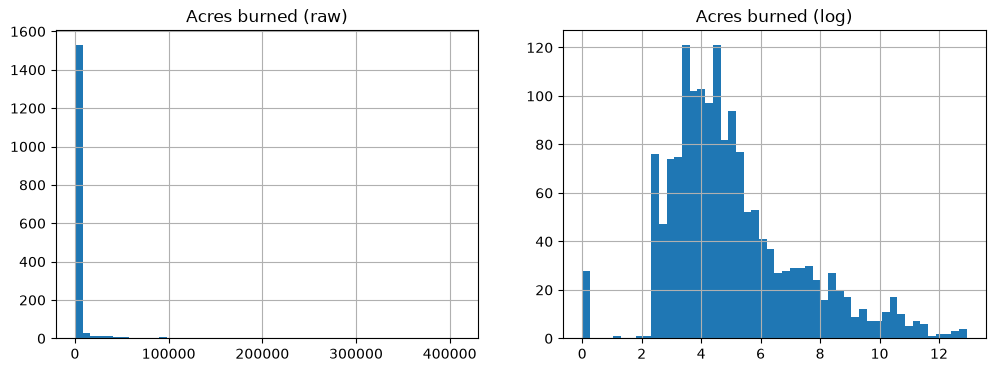

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["AcresBurned"].hist(bins=50, ax=axes[0])
axes[0].set_title("Acres burned (raw)")

y.hist(bins=50, ax=axes[1])
axes[1].set_title("Acres burned (log)")

plt.show()

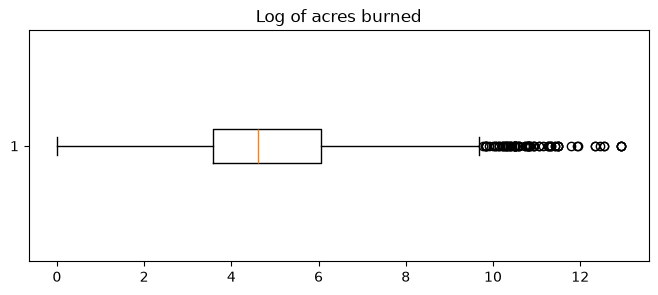

In [12]:
plt.figure(figsize=(8, 3))
plt.boxplot(y.dropna().values, orientation="horizontal")
plt.title("Log of acres burned")
plt.show()

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
x = df.drop(columns =["AcresBurned"])

In [15]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [16]:
print(x_train.shape, x_test.shape)
print(y_train.shape, y_test.shape)

(1308, 39) (328, 39)
(1308,) (328,)
